# 7-2 漏斗、留存与同期群

请选择 `Python (da-course)` 内核，从 `notebooks/` 打开。本课使用虚构的“墨读 App”三张表（`app_users.csv`、`app_events.csv`、`app_active.csv`，6000 名新用户），练习转化漏斗、留存率与同期群分析。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd
import matplotlib.pyplot as plt

读取三张表并检查日期范围。观察期截至 2025-10-31，而注册截至 2025-09-28，因此每位用户都具备完整的 30 天留存观察窗口。

In [2]:
users = pd.read_csv("../data/app/app_users.csv", parse_dates=["register_date"], encoding="utf-8-sig")
events = pd.read_csv("../data/app/app_events.csv", parse_dates=["event_time"], encoding="utf-8-sig")
active = pd.read_csv("../data/app/app_active.csv", parse_dates=["active_date"], encoding="utf-8-sig")
print("users:", users.shape, "events:", events.shape, "active:", active.shape)
print("注册区间：", users["register_date"].min().date(), "~", users["register_date"].max().date())
print("活跃区间：", active["active_date"].min().date(), "~", active["active_date"].max().date())

users: (6000, 5) events: (15243, 3) active: (34166, 2)
注册区间： 2025-07-01 ~ 2025-09-28
活跃区间： 2025-07-01 ~ 2025-10-28


## 1. 转化漏斗：按唯一用户数计算每一步流失

In [3]:
STEPS = ["app_open", "view_course", "start_trial", "click_pay", "pay_success"]
counts = [events.loc[events["event_name"].eq(st), "user_id"].nunique() for st in STEPS]
funnel = pd.DataFrame({
    "step": STEPS,
    "users": counts,
    "step_rate": [1.0] + [counts[i] / counts[i - 1] for i in range(1, len(counts))],
    "overall_rate": [c / counts[0] for c in counts],
})
funnel

,step,users,step_rate,overall_rate
0,app_open,6000,1.000000,1.000000
1,view_course,4927,0.821167,0.821167
2,start_trial,2640,0.535823,0.440000
3,click_pay,1081,0.409470,0.180167
4,pay_success,595,0.550416,0.099167


从 `start_trial`（2640 人）到 `click_pay`（1081 人），环节转化率仅 40.95%，是五步中流失最明显的瓶颈。

## 2. 留存曲线：用 active_date - register_date 计算留存天数

In [4]:
au = active.merge(users[["user_id", "register_date", "channel"]], on="user_id", how="left", validate="many_to_one")
au["day_diff"] = (au["active_date"] - au["register_date"]).dt.days
for d in [1, 7, 14, 30]:
    r = au.loc[au["day_diff"].eq(d), "user_id"].nunique() / len(users)
    print(f"D{d:2d} 留存率：{r:.2%}")

D 1 留存率：40.88%
D 7 留存率：17.82%
D14 留存率：13.68%
D30 留存率：9.97%


画出 D0~D30 的留存曲线。

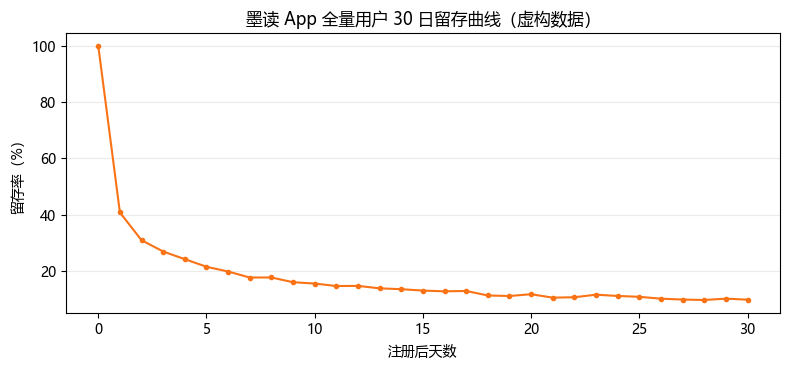

In [5]:
setup_chinese_font()
curve = au.loc[au["day_diff"].between(0, 30)].groupby("day_diff")["user_id"].nunique() / len(users)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curve.index, curve.values * 100, marker="o", markersize=3, color="#f97316")
ax.set(title="墨读 App 全量用户 30 日留存曲线（虚构数据）", xlabel="注册后天数", ylabel="留存率（%）")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 练习 7-2.1 App 五步转化漏斗表

按 `["app_open", "view_course", "start_trial", "click_pay", "pay_success"]` 顺序计算 `step, users, step_rate, overall_rate`。

In [6]:
steps_ex = ["app_open", "view_course", "start_trial", "click_pay", "pay_success"]
cnt_ex = [events.loc[events["event_name"].eq(st), "user_id"].nunique() for st in steps_ex]
ans_7_2_1 = pd.DataFrame([
    {
        "step": st,
        "users": u,
        "step_rate": 1.0 if i == 0 else u / cnt_ex[i - 1],
        "overall_rate": u / cnt_ex[0],
    }
    for i, (st, u) in enumerate(zip(steps_ex, cnt_ex))
])
check("7-2.1", ans_7_2_1)

True

## 练习 7-2.2 全量用户 D1/D7/D14/D30 留存率

计算全量用户的 D1、D7、D14、D30 留存率（0~1 小数），存入字典 `ans_7_2_2`（键：`d1, d7, d14, d30`）。

In [7]:
au_ex = active.merge(users[["user_id", "register_date"]], on="user_id", how="left", validate="many_to_one")
au_ex["day_diff"] = (au_ex["active_date"] - au_ex["register_date"]).dt.days
ans_7_2_2 = {
    f"d{d}": au_ex.loc[au_ex["day_diff"].eq(d), "user_id"].nunique() / len(users)
    for d in (1, 7, 14, 30)
}
check("7-2.2", ans_7_2_2)

True

## 练习 7-2.3 各渠道 7 日留存率对比

按 `channel` 统计注册人数 `users`、第 7 日活跃唯一人数 `d7_retained` 与 `d7_rate`，按 `d7_rate` 降序排列。

In [8]:
au_ch = active.merge(users[["user_id", "register_date", "channel"]], on="user_id", how="left", validate="many_to_one")
au_ch["day_diff"] = (au_ch["active_date"] - au_ch["register_date"]).dt.days
base_ch = users.groupby("channel", as_index=False).agg(users=("user_id", "nunique"))
d7_ch = au_ch.loc[au_ch["day_diff"].eq(7)].groupby("channel", as_index=False).agg(d7_retained=("user_id", "nunique"))
ans_7_2_3 = base_ch.merge(d7_ch, on="channel", how="left")
ans_7_2_3["d7_retained"] = ans_7_2_3["d7_retained"].fillna(0).astype(int)
ans_7_2_3["d7_rate"] = ans_7_2_3["d7_retained"] / ans_7_2_3["users"]
ans_7_2_3 = ans_7_2_3.sort_values("d7_rate", ascending=False).reset_index(drop=True)
check("7-2.3", ans_7_2_3)

True

## 练习 7-2.4 按注册月份制作同期群留存表

提取 `register_month = register_date.dt.strftime("%Y-%m")`，按月统计 `users, d1, d7, d30`，按 `register_month` 升序排列。

In [9]:
u_m = users.copy()
u_m["register_month"] = u_m["register_date"].dt.strftime("%Y-%m")
au_m = active.merge(u_m[["user_id", "register_date", "register_month"]], on="user_id", how="left", validate="many_to_one")
au_m["day_diff"] = (au_m["active_date"] - au_m["register_date"]).dt.days
coh = u_m.groupby("register_month", as_index=False).agg(users=("user_id", "nunique"))
for d in (1, 7, 30):
    sub = au_m.loc[au_m["day_diff"].eq(d)].groupby("register_month", as_index=False).agg(**{f"n{d}": ("user_id", "nunique")})
    coh = coh.merge(sub, on="register_month", how="left")
    coh[f"d{d}"] = coh[f"n{d}"].fillna(0) / coh["users"]
ans_7_2_4 = coh[["register_month", "users", "d1", "d7", "d30"]].sort_values("register_month").reset_index(drop=True)
check("7-2.4", ans_7_2_4)

True